# Predictive maintenance: where failures cost most, and an alert that pays for itself

**The question a plant maintenance manager asks before next year's budget:** *where do unplanned failures cost us most, do the machines warn us before they fail, and would replacing parts based on those warnings pay off?*

This notebook is the self-contained version of a larger portfolio project (PostgreSQL, Python and an Excel business case). It runs on the five raw files of the [Microsoft Azure Predictive Maintenance](https://www.kaggle.com/datasets/arnabbiswas1/microsoft-azure-predictive-maintenance) dataset: 100 machines, one year (2015), 876,100 hourly sensor readings.

**What it shows**
1. Where failures concentrate (Pareto, MTBF)
2. That each component has its own warning signature, visible on per-machine control charts
3. A simple alert rule, chosen on January–August and tested on September–December: **97% of failures caught, 86% of alerts real, about 19 hours of notice**

> The dataset is synthetic: its warning signs are cleaner than a real plant's. Read the results as what this method would show on real data.

## Setup

Shared helpers: loading, control limits, turning a rule into alerts, and scoring alerts against failures.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = REPO_ROOT / "data" / "raw"
EXPORT_DIR = REPO_ROOT / "data" / "exports"
IMAGE_DIR = REPO_ROOT / "images"

SENSORS = ["volt", "rotate", "pressure", "vibration"]
SENSOR_LABEL = {"volt": "Voltage", "rotate": "Rotation", "pressure": "Pressure", "vibration": "Vibration"}
COMPONENTS = ["comp1", "comp2", "comp3", "comp4"]

# Train/test split for the alert rules: rules and thresholds are chosen on TRAIN only.
TRAIN = (pd.Timestamp("2015-01-01"), pd.Timestamp("2015-09-01"))
TEST = (pd.Timestamp("2015-09-01"), pd.Timestamp("2016-01-02"))

# Colours (validated reference palette; see the README's chart notes)
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]     # categorical slots 1-4, fixed order
CRITICAL = "#d03b3b"                                         # out-of-control points, failures


# --------------------------------------------------------------------------- style
def set_style() -> None:
    """Quiet axes, hairline grid, readable type: the look of every chart in the repo."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
        "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "axes.titlepad": 10,
        "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.axisbelow": True, "text.color": INK,
        "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
        "legend.frameon": False, "lines.linewidth": 2,
    })


def save(fig, name: str) -> Path:
    IMAGE_DIR.mkdir(exist_ok=True)
    path = IMAGE_DIR / name
    fig.savefig(path)
    return path


# --------------------------------------------------------------------------- data
def load_raw() -> dict[str, pd.DataFrame]:
    """The five Kaggle tables with snake_case columns, sorted by machine and time."""
    rename = {"machineID": "machine_id", "errorID": "error_id", "failure": "comp"}
    out = {}
    for name in ["telemetry", "errors", "maint", "failures", "machines"]:
        df = pd.read_csv(RAW_DIR / f"PdM_{name}.csv").rename(columns=rename)
        if "datetime" in df:
            df["datetime"] = pd.to_datetime(df["datetime"])
            df = df.sort_values(["machine_id", "datetime"]).reset_index(drop=True)
        out[name] = df
    return out


def failure_events(failures: pd.DataFrame) -> pd.DataFrame:
    """One row per machine + hour (761 component failures -> 719 events)."""
    return (failures.groupby(["machine_id", "datetime"])["comp"]
            .agg(lambda s: ", ".join(sorted(s))).rename("components").reset_index())


def load_export(view: str) -> pd.DataFrame:
    """A CSV written by src/export_views.py."""
    return pd.read_csv(EXPORT_DIR / f"{view}.csv")


# --------------------------------------------------------------------------- control limits
def add_daily_mean(tel: pd.DataFrame, hours: int = 24) -> pd.DataFrame:
    """Rolling mean of each sensor over the last `hours` hours (column <sensor>_24h).

    Hourly readings are noisy; a failure shows as a shift lasting a day or more, which the
    daily mean makes visible. The first 23 hours of each machine have no value.
    """
    tel = tel.sort_values(["machine_id", "datetime"]).reset_index(drop=True)
    rolled = (tel.groupby("machine_id")[SENSORS]
              .rolling(hours, min_periods=hours).mean().reset_index(level=0, drop=True))
    for s in SENSORS:
        tel[f"{s}_24h"] = rolled[s]
    return tel


def baseline_limits(tel: pd.DataFrame, events: pd.DataFrame, days: int = 30,
                    exclude_before_days: int = 7, exclude_after_days: int = 2) -> pd.DataFrame:
    """Centre line and sigma per machine and sensor, from that machine's own normal running.

    Baseline = the first `days` days of data, minus the `exclude_before_days` before any
    failure and the `exclude_after_days` after it (the daily mean is still disturbed then).
    Returns one row per machine with <sensor>_mean and <sensor>_sd columns.
    """
    start = tel["datetime"].min()
    base = tel[(tel["datetime"] < start + pd.Timedelta(days=days)) & tel[f"{SENSORS[0]}_24h"].notna()]
    ev = events[events["datetime"] < start + pd.Timedelta(days=days + exclude_before_days)]
    keep = np.ones(len(base), dtype=bool)
    for r in ev.itertuples():
        keep &= ~((base["machine_id"].values == r.machine_id)
                  & (base["datetime"].values >= np.datetime64(r.datetime - pd.Timedelta(days=exclude_before_days)))
                  & (base["datetime"].values < np.datetime64(r.datetime + pd.Timedelta(days=exclude_after_days))))
    base = base[keep]
    agg = base.groupby("machine_id")[[f"{s}_24h" for s in SENSORS]].agg(["mean", "std", "count"])
    out = pd.DataFrame(index=agg.index)
    for s in SENSORS:
        out[f"{s}_mean"] = agg[(f"{s}_24h", "mean")]
        out[f"{s}_sd"] = agg[(f"{s}_24h", "std")]
    out["baseline_hours"] = agg[(f"{SENSORS[0]}_24h", "count")]
    return out.reset_index()


def add_z(tel: pd.DataFrame, limits: pd.DataFrame) -> pd.DataFrame:
    """Distance of each daily mean from its machine's centre line, in baseline sigmas (<sensor>_z)."""
    lim = tel[["machine_id"]].merge(limits, on="machine_id", how="left")
    for s in SENSORS:
        tel[f"{s}_z"] = (tel[f"{s}_24h"].values - lim[f"{s}_mean"].values) / lim[f"{s}_sd"].values
    return tel


def hours_since_replacement(tel: pd.DataFrame, maint: pd.DataFrame) -> np.ndarray:
    """Hours since the last component replacement on the machine (NaN if none yet)."""
    reps = maint[["machine_id", "datetime"]].drop_duplicates().rename(columns={"datetime": "rep"})
    left = tel[["machine_id", "datetime"]].reset_index()
    joined = pd.merge_asof(left.sort_values("datetime"), reps.sort_values("rep"),
                           left_on="datetime", right_on="rep", by="machine_id", direction="backward")
    joined = joined.sort_values("index")
    return ((joined["datetime"] - joined["rep"]).dt.total_seconds() / 3600).values


def recent_error(tel: pd.DataFrame, errors: pd.DataFrame, codes: list[str] | None = None,
                 hours: int = 24) -> np.ndarray:
    """True for each machine-hour with at least one of `codes` (all codes if None) in the last `hours`."""
    e = errors if codes is None else errors[errors["error_id"].isin(codes)]
    marks = e[["machine_id", "datetime"]].drop_duplicates().assign(hit=1)
    grid = tel[["machine_id", "datetime"]].merge(marks, how="left", on=["machine_id", "datetime"])
    grid["hit"] = grid["hit"].fillna(0)
    rolled = grid.groupby("machine_id")["hit"].transform(lambda s: s.rolling(hours, min_periods=1).sum())
    return (rolled > 0).values


# --------------------------------------------------------------------------- alerts
def alerts_from_flag(tel: pd.DataFrame, flag, min_hours: int = 1, merge_days: int = 7) -> pd.DataFrame:
    """Turn an hourly True/False condition into alerts.

    An alert fires in the hour the condition has held for `min_hours` hours in a row.
    Further firings on the same machine within `merge_days` of an alert belong to that alert
    (one technician visit, not seven).
    """
    df = tel[["machine_id", "datetime"]].copy()
    df["f"] = np.asarray(flag, dtype=bool)
    run_id = ((df["f"] != df["f"].shift()) | (df["machine_id"] != df["machine_id"].shift())).cumsum()
    df["run"] = df["f"].astype(int).groupby(run_id).cumsum()
    hits = df[df["f"] & (df["run"] >= min_hours)]
    out, gap = [], pd.Timedelta(days=merge_days)
    for mid, g in hits.groupby("machine_id"):
        last = None
        for ts in g["datetime"]:
            if last is None or ts - last > gap:
                out.append((mid, ts))
                last = ts
    return pd.DataFrame(out, columns=["machine_id", "datetime"])


def match_alerts(alerts: pd.DataFrame, events: pd.DataFrame, horizon_days: int = 7):
    """Pair alerts with the failures they warned about.

    An alert is TRUE when the same machine has a failure event 0-`horizon_days` days after it.
    A failure is CAUGHT when at least one alert came in the `horizon_days` before it; its lead
    time is measured from the EARLIEST such alert.
    Returns (alerts with is_true, events with caught and lead_hours).
    """
    j = alerts.reset_index().merge(events.reset_index(), on="machine_id", suffixes=("", "_f"))
    j = j[(j["datetime_f"] > j["datetime"]) & (j["datetime_f"] <= j["datetime"] + pd.Timedelta(days=horizon_days))]
    a = alerts.copy()
    a["is_true"] = a.index.isin(j["index"])
    first = j.groupby("index_f")["datetime"].min()
    e = events.copy()
    e["caught"] = e.index.isin(first.index)
    e["lead_hours"] = (e["datetime"] - e.index.map(first)).dt.total_seconds() / 3600
    return a, e


def score(alerts: pd.DataFrame, events: pd.DataFrame, period: tuple, horizon_days: int = 7) -> dict:
    """Recall, precision and lead time of a set of alerts within a period [start, end)."""
    lo, hi = period
    a = alerts[(alerts["datetime"] >= lo) & (alerts["datetime"] < hi)].reset_index(drop=True)
    e = events[(events["datetime"] >= lo) & (events["datetime"] < hi)].reset_index(drop=True)
    a, e = match_alerts(a, e, horizon_days)
    n_true = int(a["is_true"].sum())
    return {
        "failures": len(e),
        "caught": int(e["caught"].sum()),
        "missed": int((~e["caught"]).sum()),
        "alerts": len(a),
        "true_alerts": n_true,
        "false_alarms": len(a) - n_true,
        "recall": e["caught"].mean() if len(e) else np.nan,
        "precision": n_true / len(a) if len(a) else np.nan,
        "median_lead_hours": e.loc[e["caught"], "lead_hours"].median(),
    }

In [2]:
# Find the data: Kaggle input folder, or data/raw/ in the GitHub repo
from pathlib import Path
hits = list(Path("/kaggle/input").rglob("PdM_telemetry.csv")) if Path("/kaggle/input").exists() else []
RAW_DIR = hits[0].parent if hits else REPO_ROOT / "data" / "raw"
print("Reading data from", RAW_DIR)

set_style()
pd.set_option("display.width", 140)
raw = load_raw()
tel, errors, maint, failures, machines = (raw[k] for k in ["telemetry", "errors", "maint", "failures", "machines"])
events = failure_events(failures)
for name, df in raw.items():
    print(f"{name:<10} {len(df):>9,} rows")

Reading data from /home/claude/pdm/data/raw


telemetry    876,100 rows
errors         3,919 rows
maint          3,286 rows
failures         761 rows
machines         100 rows


## Data checks

Before any analysis: every machine has a reading for every hour, nothing is missing, and the failure count splits into stoppages. Two components can fail in the same stoppage, so the 761 failed parts are 719 stoppages (failure events).

In [3]:
per_machine_hours = tel.groupby("machine_id").size()
gaps = tel.groupby("machine_id")["datetime"].diff().dropna().ne(pd.Timedelta(hours=1)).sum()
print(f"Hourly readings per machine: {per_machine_hours.min():,} to {per_machine_hours.max():,}; gaps: {gaps}")
print(f"Missing values: {int(sum(df.isna().sum().sum() for df in raw.values()))}")
print(f"Failed parts: {len(failures)}, failure events (stoppages): {len(events)}, "
      f"with 2+ parts: {(events['components'].str.contains(',')).sum()}")

Hourly readings per machine: 8,761 to 8,761; gaps: 0
Missing values: 0
Failed parts: 761, failure events (stoppages): 719, with 2+ parts: 42


## 1. Where do failures concentrate?

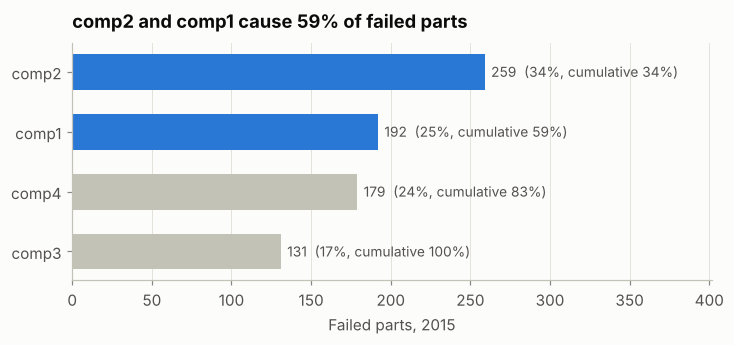

In [4]:
comp = failures["comp"].value_counts().rename("failures").to_frame()
comp["pct"] = comp["failures"] / comp["failures"].sum()
comp["cum_pct"] = comp["pct"].cumsum()

fig, ax = plt.subplots(figsize=(7.5, 2.8))
c = comp.iloc[::-1]
ax.barh(c.index, c["failures"], color=[SERIES[0] if v >= c["failures"].nlargest(2).min() else AXIS for v in c["failures"]], height=0.6)
for y, (n, p, cp) in enumerate(zip(c["failures"], c["pct"], c["cum_pct"])):
    ax.text(n + 4, y, f"{n}  ({p:.0%}, cumulative {cp:.0%})", va="center", color=INK_2, fontsize=9)
ax.set_xlim(0, c["failures"].max() * 1.55); ax.grid(axis="y", visible=False)
ax.set_xlabel("Failed parts, 2015")
ax.set_title(f"{comp.index[0]} and {comp.index[1]} cause {comp['cum_pct'].iloc[1]:.0%} of failed parts")
plt.show()

In [5]:
hours = (tel["datetime"].max() - tel["datetime"].min()) / pd.Timedelta(hours=1)
per_m = machines.merge(events.groupby("machine_id").size().rename("events"), on="machine_id", how="left").fillna({"events": 0})
by_model = per_m.groupby("model").agg(machines=("machine_id", "count"), avg_age=("age", "mean"), events=("events", "sum"))
by_model["events_per_machine"] = by_model["events"] / by_model["machines"]
by_model["mtbf_days"] = by_model["machines"] * hours / by_model["events"] / 24
by_model["share_of_fleet"] = by_model["machines"] / by_model["machines"].sum()
by_model["share_of_events"] = by_model["events"] / by_model["events"].sum()
r = per_m[["age", "events"]].corr().iloc[0, 1]
print(f"Age vs failures: r = {r:.2f}; slope {np.polyfit(per_m['age'], per_m['events'], 1)[0]:.2f} failures per year of age")
by_model.round(2)

Age vs failures: r = 0.46; slope 0.26 failures per year of age


,machines,avg_age,events,events_per_machine,mtbf_days,share_of_fleet,share_of_events
model,,,,,,,
model1,16,12.25,175.0,10.94,33.37,0.16,0.24
model2,17,12.76,160.0,9.41,38.78,0.17,0.22
model3,35,12.03,212.0,6.06,60.26,0.35,0.29
model4,32,9.34,172.0,5.38,67.91,0.32,0.24


**model1 and model2 are a third of the fleet but cause 47% of stoppages**, with a mean time between failures (MTBF = operating hours ÷ failures) of 33–39 days against 60–68 for model3 and model4. Their average age is similar, so age doesn't explain the gap; older machines do fail more often, separately from model.

## 2. Do the machines warn us? Control charts per machine

Each sensor is smoothed to a 24-hour mean, then compared with **that machine's own normal**: centre line and ±3σ limits from its first 30 days (minus the days around any failure). The limits use the standard deviation of the baseline 24-hour means, because consecutive rolling means share 23 of 24 readings and a moving-range estimate would be far too tight.

In [6]:
tel = add_daily_mean(tel)
limits = baseline_limits(tel, events)
tel = add_z(tel, limits)

# average distance from normal (σ) in the 48 h before each component fails
zt = tel.set_index(["machine_id", "datetime"])[[f"{s}_z" for s in SENSORS]]
pre = []
for f in failures.itertuples():
    idx = pd.MultiIndex.from_arrays([np.full(48, f.machine_id), f.datetime - pd.to_timedelta(np.arange(1, 49), unit="h")])
    pre.append(pd.DataFrame(zt.reindex(idx).to_numpy(), columns=SENSORS).assign(comp=f.comp))
pd.concat(pre).groupby("comp")[SENSORS].mean().round(1)

,volt,rotate,pressure,vibration
comp,,,,
comp1,4.6,-0.5,0.2,0.3
comp2,0.2,-5.2,0.4,0.6
comp3,0.2,-0.3,8.0,0.3
comp4,0.1,-0.6,0.5,7.2


Each component has one sensor that moves far from normal in the 48 hours before it fails: **voltage up before comp1, rotation down before comp2, pressure up before comp3, vibration up before comp4.** Here is vibration on the machine with the most comp4 failures.

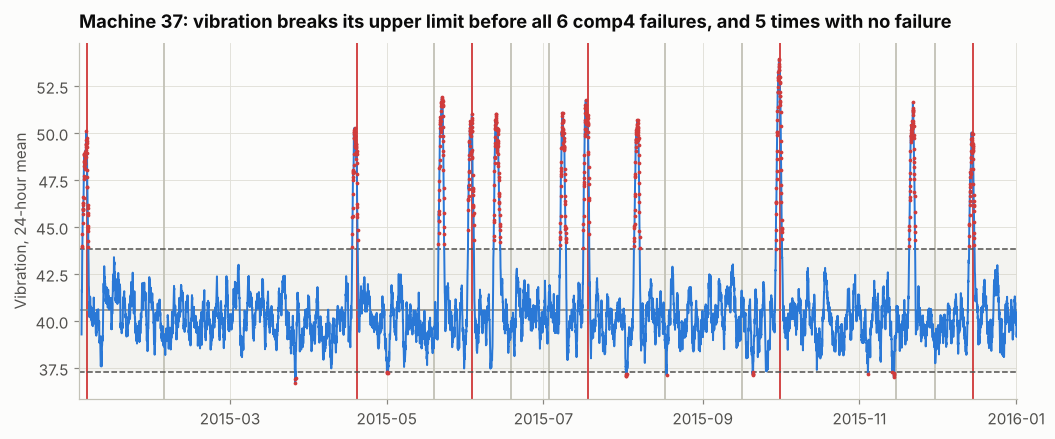

In [7]:
comp4 = failures[failures["comp"] == "comp4"]
m_id = comp4["machine_id"].value_counts().idxmax()
d = tel[tel["machine_id"] == m_id].reset_index(drop=True)
lim = limits.set_index("machine_id").loc[m_id]
mu, sd = lim["vibration_mean"], lim["vibration_sd"]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axhspan(mu - 3 * sd, mu + 3 * sd, color=AXIS, alpha=0.15, linewidth=0)
ax.axhline(mu, color=MUTED, linewidth=1)
for v in (mu - 3 * sd, mu + 3 * sd):
    ax.axhline(v, color=INK_2, linewidth=1, linestyle="--")
ax.plot(d["datetime"], d["vibration_24h"], color=SERIES[0], linewidth=1.3)
out = d["vibration_z"].abs() > 3
ax.scatter(d.loc[out, "datetime"], d.loc[out, "vibration_24h"], color=CRITICAL, s=6, zorder=3, linewidth=0)
for r_ in failures[failures["machine_id"] == m_id].itertuples():
    ax.axvline(r_.datetime, color=CRITICAL if r_.comp == "comp4" else AXIS, linewidth=1.2, zorder=1)

exc = alerts_from_flag(d, d["vibration_z"] > 3, min_hours=1, merge_days=7)
exc, _ = match_alerts(exc, comp4[comp4["machine_id"] == m_id].reset_index(drop=True))
ax.set_xlim(d["datetime"].min(), d["datetime"].max())
ax.set_ylabel("Vibration, 24-hour mean")
ax.set_title(f"Machine {m_id}: vibration breaks its upper limit before all {int(exc['is_true'].sum())} comp4 failures, "
             f"and {int((~exc['is_true']).sum())} times with no failure")
plt.show()

The warning is real, but **a control limit alone raises false alarms**. The error codes help: each component also has its own error code in the hours before it fails (error1 → comp1, error2/3 → comp2, error4 → comp3, error5 → comp4).

## 3. How good would an alert be?

Five rules, scored the same way:

- An **alert** is the hour a rule fires; repeat firings within 7 days are one alert, and there are no alerts in the 48 hours after a part replacement.
- An alert is **true** if a failure follows within 7 days. **Recall** = failures caught; **precision** = alerts that are true.
- Thresholds and the final rule are chosen on **January–August**; the numbers that count are on **September–December**. The selection criterion, fixed in advance, is the highest precision among rules that catch at least 90% of failures.

In [8]:
settled = ~(hours_since_replacement(tel, maint) < 48)
direction = {"volt": 1, "rotate": -1, "pressure": 1, "vibration": 1}
codes = {"volt": ["error1"], "rotate": ["error2", "error3"], "pressure": ["error4"], "vibration": ["error5"]}
code_24h = {s: recent_error(tel, errors, codes[s], 24) for s in SENSORS}
any_err_24h = recent_error(tel, errors, None, 24)
err_now = recent_error(tel, errors, None, 1)
beyond = lambda s, k: direction[s] * tel[f"{s}_z"].values > k
any_beyond = lambda k: np.logical_or.reduce([beyond(s, k) for s in SENSORS])

def rule(name, k=3.0):
    return {"A. Vibration only": beyond("vibration", k),
            "B. Any sensor": any_beyond(k),
            "C. Any error code": err_now,
            "D. Sensor + any error": any_beyond(k) & any_err_24h,
            "E. Signature match": np.logical_or.reduce([beyond(s, k) & code_24h[s] for s in SENSORS])}[name]

# choose rule E's threshold on the TRAINING period
grid = []
for k in [2.0, 2.5, 3.0, 3.5, 4.0]:
    for h in [1, 6]:
        al = alerts_from_flag(tel, rule("E. Signature match", k) & settled, min_hours=h)
        grid.append({"threshold_sigma": k, "hours_in_a_row": h, **score(al, events, TRAIN)})
grid = pd.DataFrame(grid)
best = grid[grid["recall"] >= 0.9].sort_values(["precision", "median_lead_hours"], ascending=False).iloc[0]
print(f"Chosen on Jan-Aug: {best['threshold_sigma']}σ for {int(best['hours_in_a_row'])} hour(s) in a row "
      f"(train recall {best['recall']:.1%}, precision {best['precision']:.1%})")
grid.round(3)

Chosen on Jan-Aug: 2.5σ for 6 hour(s) in a row (train recall 93.9%, precision 89.6%)


,threshold_sigma,hours_in_a_row,failures,caught,missed,alerts,true_alerts,false_alarms,recall,precision,median_lead_hours
0,2.0,1,493,475,18,648,475,173,0.963,0.733,24.0
1,2.0,6,493,472,21,559,472,87,0.957,0.844,19.0
2,2.5,1,493,470,23,574,470,104,0.953,0.819,24.0
3,2.5,6,493,463,30,517,463,54,0.939,0.896,19.0
4,3.0,1,493,456,37,520,456,64,0.925,0.877,24.0
5,3.0,6,493,439,54,482,439,43,0.890,0.911,19.0
6,3.5,1,493,424,69,474,424,50,0.860,0.895,24.0
7,3.5,6,493,407,86,439,407,32,0.826,0.927,19.0
8,4.0,1,493,389,104,425,389,36,0.789,0.915,24.0
9,4.0,6,493,371,122,395,371,24,0.753,0.939,19.0


In [9]:
# every rule family on the TEST period (A-D at the settings chosen in the full project's training step)
settings = {"A. Vibration only": (3.0, 6), "B. Any sensor": (4.0, 6), "C. Any error code": (3.0, 1),
            "D. Sensor + any error": (4.0, 6), "E. Signature match": (best["threshold_sigma"], int(best["hours_in_a_row"]))}
test = pd.DataFrame([{"rule": n, **score(alerts_from_flag(tel, rule(n, k) & settled, min_hours=h), events, TEST)}
                     for n, (k, h) in settings.items()]).set_index("rule")
test[["failures", "caught", "alerts", "false_alarms", "recall", "precision", "median_lead_hours"]].round(3)

,failures,caught,alerts,false_alarms,recall,precision,median_lead_hours
rule,,,,,,,
A. Vibration only,226,64,229,165,0.283,0.279,37.0
B. Any sensor,226,179,567,388,0.792,0.316,33.0
C. Any error code,226,208,670,462,0.920,0.310,24.0
D. Sensor + any error,226,179,257,78,0.792,0.696,19.0
E. Signature match,226,220,256,36,0.973,0.859,19.0


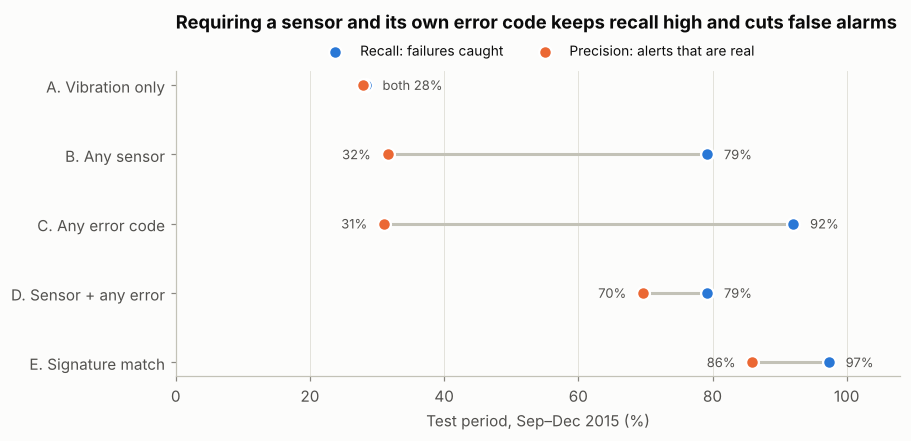

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
t = test.iloc[::-1]
for y, (rec, pre) in enumerate(zip(t["recall"] * 100, t["precision"] * 100)):
    ax.plot([pre, rec], [y, y], color=AXIS, linewidth=2, zorder=1)
    if abs(rec - pre) < 5:
        ax.text(max(rec, pre) + 2.5, y, f"both {rec:.0f}%", va="center", color=INK_2, fontsize=8.5)
    else:
        ax.text(rec + 2.5, y, f"{rec:.0f}%", va="center", color=INK_2, fontsize=8.5)
        ax.text(pre - 2.5, y, f"{pre:.0f}%", va="center", ha="right", color=INK_2, fontsize=8.5)
ax.scatter(t["recall"] * 100, range(len(t)), color=SERIES[0], s=70, zorder=2, label="Recall: failures caught", edgecolor="white", linewidth=1.5)
ax.scatter(t["precision"] * 100, range(len(t)), color=SERIES[1], s=70, zorder=2, label="Precision: alerts that are real", edgecolor="white", linewidth=1.5)
ax.set_yticks(range(len(t)), t.index)
ax.set_xlim(0, 108); ax.grid(axis="y", visible=False)
ax.set_xlabel("Test period, Sep–Dec 2015 (%)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=9)
ax.set_title("Requiring a sensor and its own error code keeps recall high and cuts false alarms", pad=28)
plt.show()

## Findings

- **Failures concentrate:** comp2 and comp1 cause 59% of failed parts; model1 and model2 fail about twice as often as model3 and model4.
- **The machines warn about a day ahead:** each component has its own sensor signature and error code in the 48 hours before it fails.
- **One signal is not enough:** a single sensor or "any error code" raises far more false alarms than real ones.
- **Two signals together work:** a sensor past its control limit **and** its own error code in the last 24 hours, chosen on January–August, caught **220 of 226 failures (97%)** on September–December with **86% of alerts real** and about **19 hours of notice**.
- **The business case** (in the full project's Excel model, with labelled cost assumptions in PLN) puts the base-case saving at **11.8 million PLN a year, 34% of maintenance cost**, falling to a small loss only if the alert is much weaker on real data and stops are short and cheap.

*Synthetic data: expect lower recall and precision on a real plant. The method (limits per machine, a rule chosen on one period and tested on another) carries over unchanged.*